#### Generador atmosférico por vecinos (k-NN) en vez del PVAR
En cada paso se busca, en la historia y en la misma época del año, el estado de PCs más parecido al estado simulado actual, se elige uno de los k más cercanos (pesos 1/rango, Lall & Sharma 1996) y se copian los B pasos reales que le siguieron. La serie simulada son trozos de atmósfera real empalmados: las configuraciones de temporal llegan intactas.

Después: mismo XGB (04B) y mismo modelo de ruido (05C) que en 08, y las mismas métricas.

In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from scipy.stats import genextreme
from scipy.signal import find_peaks
from utils.tv_var.periodic_var import PeriodicVAR

In [2]:
import pickle, json, glob, os, time
from utils.pit.piece_wise_marginal import from_normal

waves_df = pd.read_csv("inputs/waves_bulk.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open("outputs/marginal/transformacion.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

In [3]:
#### Regresión final de 04B y modelo de ruido final de 05C (igual que en 08)
xgb_final = XGBRegressor()
xgb_final.load_model("outputs/xgb_pit/xgb_final.json")
feat = json.load(open("outputs/xgb_pit/xgb_features.json"))
cols, lags = feat["columns"], feat["lags_h"]

esc = pickle.load(open("outputs/xgb_pit/escala.pkl", "rb"))
bordes, sigma, pools_r, results_u, L = esc["bordes"], esc["sigma"], esc["pools_r"], esc["results_u"], esc["L"]
SUAVIZADO_H = esc.get("suavizado_h", 1)

e_u = results_u.resid_["r"].asfreq("h")
ev = e_u.values
inicios = np.flatnonzero(np.convolve(~np.isnan(ev), np.ones(L), "valid") == L)

def ruido_bloques(n, L, rng):
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios)
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]
        t += m
    return out

def mapear(r, dec):
    """Mapeo de cuantiles por decil: r toma la forma de r_oof de su decil."""
    out = np.empty(len(r))
    for k in range(10):
        m = dec == k
        rk = (pd.Series(r.values[m]).rank().values - 0.5) / m.sum()
        out[m] = np.quantile(pools_r[k], rk)
    return pd.Series(out, index=r.index)

def f_desde_pcs(pcs):
    """PCs 6-horarias → f horaria (mismos lags y columnas que 04B, interpolada y suavizada como en 05C)."""
    X = pd.concat({f"l{l}": pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    X = X.dropna()[cols]
    f_6h = pd.Series(xgb_final.predict(X), index=X.index)
    f_h = f_6h.resample("h").interpolate()
    if SUAVIZADO_H > 1:
        f_h = f_h.rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
    return f_h

def hs_desde_f(f_h, rng):
    """f horaria → Hs horaria con el modelo de ruido de 05C."""
    dec = np.digitize(f_h, bordes)
    sig = pd.Series(sigma.loc[dec].values, index=f_h.index)
    ruido_df = pd.DataFrame(ruido_bloques(len(f_h), L, rng), index=f_h.index, columns=["r"])
    u = results_u.simulate(noise=ruido_df, burn=24*30)["r"]
    return hs_desde_z(f_h + mapear(u * sig, dec))

In [4]:
#### Historia: PCs reales 1941–2025 y su versión sin estacionalidad (para medir distancias)
pcs_hist = pd.read_csv("outputs/seleccion_6h/pcs_seleccionadas_6h.csv", index_col=0, parse_dates=True).loc["1941":"2025"]
harm_std_pcs = pickle.load(open("outputs/var_6h/harm_std_pcs.pkl", "rb"))
pcs_z = harm_std_pcs.transform(pcs_hist)

H = pcs_hist.values                                          # lo que se copia (unidades de PC, con estacionalidad)
Zh = pcs_z.values                                            # lo que se compara
doy_h = pcs_hist.index.day_of_year.values
n_h = len(H)
print(H.shape)

(124184, 30)


In [5]:
#### Parámetros del generador
B = 12                    # pasos que se copian tras cada elección (12 × 6 h = 3 días; con 4 los empalmes partían los temporales)
M = 2                     # pasos del estado que se comparan (los 2 últimos = 12 h)
VENTANA_DIAS = 15         # candidatos en ± 15 días de la misma época del año
EXCLUIR_DIAS = 3          # no continuar el mismo trozo (± 3 días): obliga a recombinar, no a repetir la historia
#### Distancia solo con los modos principales: con 30 dimensiones iguales todo queda "lejos" y los empalmes saltan
VARS_DIST = [f"msl_PC{i}" for i in range(1, 7)] + ["grad_PC2", "grad_PC3", "grad_PC4", "grad_PC5"]
Zd = pcs_z[VARS_DIST].values

#### Candidatos por día del año (índices de la historia con M pasos antes y B después)
validos = np.arange(M - 1, n_h - B)
cand = {}
for d in range(1, 367):
    dist_doy = np.minimum(np.abs(doy_h[validos] - d), 366 - np.abs(doy_h[validos] - d))
    cand[d] = validos[dist_doy <= VENTANA_DIAS]
k_vec = int(np.sqrt(np.median([len(v) for v in cand.values()])))   # k ≈ √n (Lall & Sharma)
pesos = 1 / np.arange(1, k_vec + 1)
pesos /= pesos.sum()
print(f"candidatos por día ≈ {np.median([len(v) for v in cand.values()]):.0f} | k = {k_vec}")

candidatos por día ≈ 10540 | k = 102


In [6]:
def simular_knn(n_anos, start, rng):
    """Serie 6-horaria de PCs empalmando trozos reales de B pasos elegidos por vecinos."""
    fechas = pd.date_range(start, periods=n_anos * 1461, freq="6h")
    n = len(fechas)
    out = np.empty((n, H.shape[1]))
    fuente = np.empty(n, dtype=int)                          # índice de la historia copiado en cada paso
    j = rng.choice(cand[fechas[M - 1].day_of_year])            # arranque: un estado real al azar de esa época
    out[:M], fuente[:M] = H[j - M + 1:j + 1], np.arange(j - M + 1, j + 1)
    t = M
    while t < n:
        estado = Zd[fuente[t - M:t]].ravel()                 # últimos M pasos simulados (en z, modos principales)
        c_ = cand[fechas[t].day_of_year]
        c_ = c_[np.abs(c_ - fuente[t - 1]) > EXCLUIR_DIAS * 4]
        D = np.stack([Zd[c_ - M + 1 + m] for m in range(M)], axis=1).reshape(len(c_), -1)
        d2 = ((D - estado) ** 2).sum(axis=1)
        idx = np.argpartition(d2, k_vec)[:k_vec]
        vecinos = c_[idx[np.argsort(d2[idx])]]                # de más cercano a más lejano
        i = rng.choice(vecinos, p=pesos)
        m = min(B, n - t)
        out[t:t + m] = H[i + 1:i + 1 + m]
        fuente[t:t + m] = np.arange(i + 1, i + 1 + m)
        t += m
    return pd.DataFrame(out, index=fechas, columns=pcs_hist.columns), fuente

In [7]:
#### Prueba rápida: 10 años, y comprobación de la atmósfera simulada
t = time.time()
pcs_k, fuente_k = simular_knn(10, "1941-01-01", np.random.default_rng(0))
print(f"10 años en {time.time() - t:.0f} s")

pcs_kz = harm_std_pcs.transform(pcs_k)
lags_6h = [1, 2, 4, 8]                                      # 6, 12, 24, 48 h
for c_ in ["msl_PC1", "grad_PC2", "grad_PC3"]:
    print(f"{c_:9s} ACF hist {np.round([pcs_z[c_].autocorr(l) for l in lags_6h], 2)} | "
          f"kNN {np.round([pcs_kz[c_].autocorr(l) for l in lags_6h], 2)}")
print(f"correlación cruzada (lag 0): máx |hist − kNN| = {np.abs(pcs_z.corr().values - pcs_kz.corr().values).max():.3f}")

#### ¿Se notan los empalmes? salto entre pasos consecutivos, en empalmes vs dentro de los trozos
salto = np.abs(np.diff(pcs_kz.values, axis=0)).mean(axis=1)
empalme = np.diff(fuente_k) != 1
print(f"salto medio |Δz|: dentro {salto[~empalme].mean():.3f} | en empalmes {salto[empalme].mean():.3f} | "
      f"historia {np.abs(np.diff(Zh, axis=0)).mean(axis=1).mean():.3f}")
print(f"años de origen distintos en 10 años simulados: {pd.Series(pcs_hist.index[fuente_k].year).nunique()}")

10 años en 2 s
msl_PC1   ACF hist [0.96 0.91 0.85 0.61] | kNN [0.94 0.87 0.79 0.53]
grad_PC2  ACF hist [0.91 0.77 0.6  0.27] | kNN [0.89 0.75 0.57 0.25]
grad_PC3  ACF hist [0.89 0.74 0.59 0.29] | kNN [0.87 0.71 0.56 0.26]


correlación cruzada (lag 0): máx |hist − kNN| = 0.076
salto medio |Δz|: dentro 0.381 | en empalmes 0.818 | historia 0.388
años de origen distintos en 10 años simulados: 85


In [8]:
#### Simulaciones largas: PCs (se guardan) → f → Hs
os.makedirs("outputs/knn_6h", exist_ok=True)
n_sims = 20                                                  # ← más si va bien
n_anos = 87

u_hist = waves_df.loc["1985":"2025", "VHM0"].quantile(0.99)   # mismo umbral de temporal que 05D y 08
am_hs, am_f, stats, q_f = [], [], [], []
for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    pcs_k, _ = simular_knn(n_anos, "1940-01-01", rng)
    pcs_k.astype("float32").to_parquet(f"outputs/knn_6h/sim_{i:03d}.parquet")
    f_h = f_desde_pcs(pcs_k).loc["1941":]
    hs = hs_desde_f(f_h, rng)
    am_hs.append(hs.groupby(hs.index.year).max().reset_index(drop=True))
    am_f.append(f_h.groupby(f_h.index.year).max().reset_index(drop=True))
    q_f.append(f_h.quantile([0.5, 0.9, 0.99, 0.999]))
    stats.append({"q99": hs.quantile(0.99), "q999": hs.quantile(0.999), "max": hs.max(),
                  "temporales/10 años": len(find_peaks(hs.values, height=u_hist, distance=72)[0]) * 10 / hs.index.year.nunique()})
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

am_hs = pd.concat(am_hs, axis=1)
am_f = pd.concat(am_f, axis=1)
stats = pd.DataFrame(stats)
pickle.dump({"am_hs": am_hs, "am_f": am_f, "stats": stats}, open("outputs/xgb_pit/am_knn.pkl", "wb"))

sim 00 (36 s)


sim 01 (34 s)


sim 02 (32 s)


sim 03 (32 s)


sim 04 (33 s)


sim 05 (33 s)


... (10 outputs left out)

sim 16 (34 s)


sim 17 (34 s)


sim 18 (33 s)


sim 19 (34 s)


#### 1. ¿El generador da una f como la histórica?

In [9]:
f_hist = f_desde_pcs(pcs_hist).loc["1942":]
am_f_hist = f_hist.groupby(f_hist.index.year).max()
q_f_sim = pd.concat(q_f, axis=1)
tabla_f = pd.DataFrame({"f histórica": f_hist.quantile([0.5, 0.9, 0.99, 0.999]),
                        "f kNN med": q_f_sim.median(axis=1),
                        "f kNN lo": q_f_sim.quantile(0.025, axis=1), "f kNN hi": q_f_sim.quantile(0.975, axis=1)})
print(tabla_f.round(3).to_string())
print(f"\nmáx. anual de f: histórica {am_f_hist.mean():.2f} ± {am_f_hist.std():.2f} | "
      f"kNN {am_f.values.mean():.2f} ± {am_f.values.std():.2f} | PVAR (08) 1.94")

       f histórica  f kNN med  f kNN lo  f kNN hi
0.500       -0.059     -0.101    -0.119    -0.090
0.900        0.972      0.893     0.886     0.924
0.990        1.951      1.866     1.835     1.917
0.999        2.644      2.550     2.520     2.616

máx. anual de f: histórica 2.62 ± 0.30 | kNN 2.52 ± 0.33 | PVAR (08) 1.94


#### 2. Hs: cuantiles altos y temporales

In [10]:
hs_obs = waves_df.loc["1985":"2025", "VHM0"]
n_obs = len(find_peaks(hs_obs.values, height=u_hist, distance=72)[0]) * 10 / hs_obs.index.year.nunique()
print(f"obs : q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f} | temporales/10 años {n_obs:.0f}")
print("05D (f histórica): temporales/10 años ≈ 67–81 | 08 (PVAR): ≈ 57")
print(stats.quantile([0.025, 0.5, 0.975]).round(2))

obs : q99 2.64 | q999 3.73 | max 5.74 | temporales/10 años 62
05D (f histórica): temporales/10 años ≈ 67–81 | 08 (PVAR): ≈ 57
        q99  q999   max  temporales/10 años
0.025  2.75  3.91  5.37               62.46
0.500  2.80  4.03  5.86               67.56
0.975  2.87  4.18  6.56               71.70


#### 3. Máximos anuales y periodos de retorno (kNN vs PVAR vs observado)

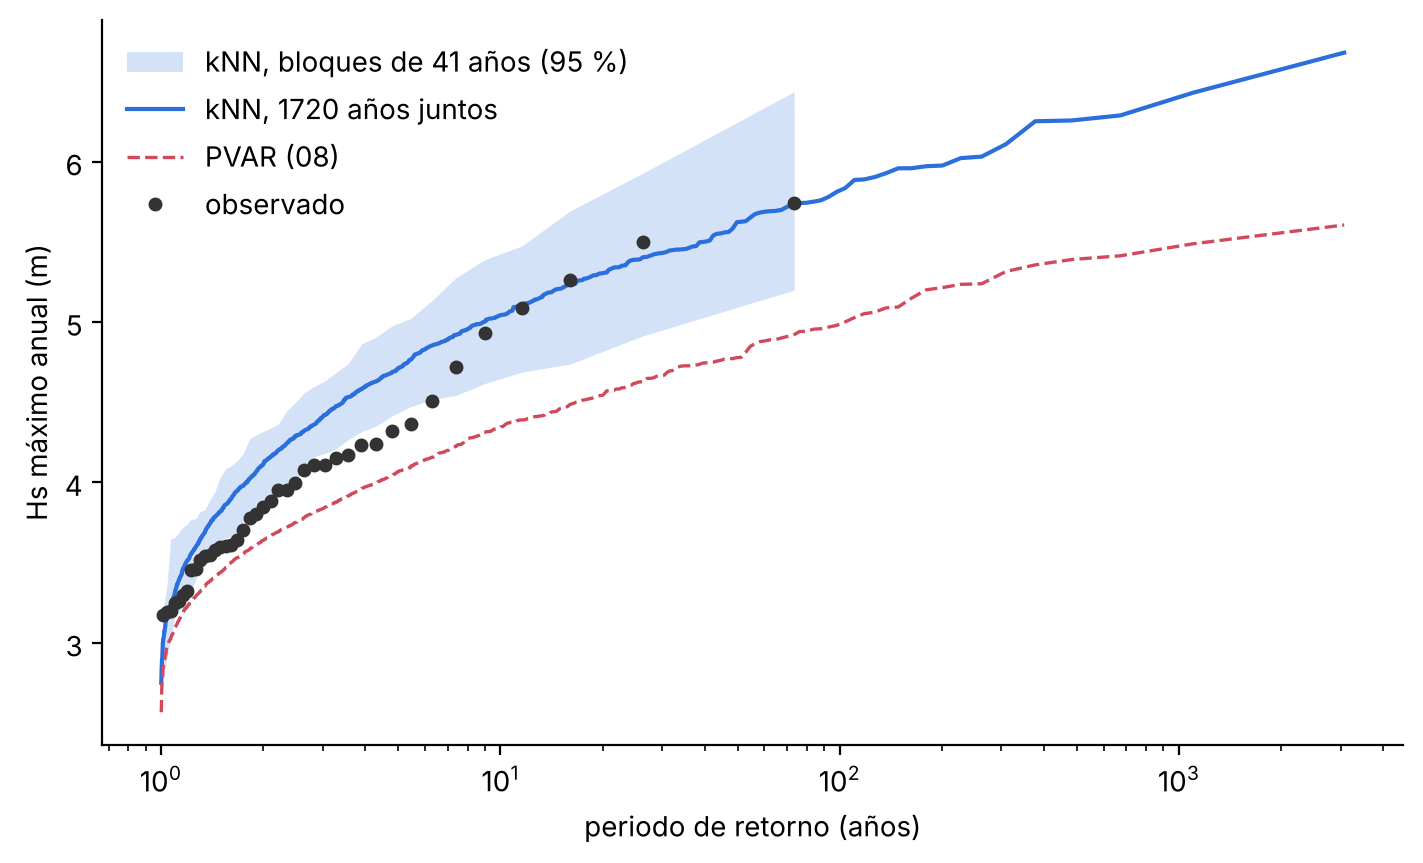

In [11]:
def gringorten(am):
    am = np.sort(np.asarray(am))
    n = len(am)
    return 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12)), am

am_obs = hs_obs.groupby(hs_obs.index.year).max()
T_obs, x_obs = gringorten(am_obs)
n_b = len(am_obs)
bloques = [am_hs[c_].values[j:j + n_b] for c_ in am_hs.columns for j in range(0, len(am_hs) - n_b + 1, n_b)]
bloques_ord = np.array([np.sort(b) for b in bloques]).T
T_b = gringorten(np.arange(n_b))[0]

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
ax.fill_between(T_b, np.percentile(bloques_ord, 2.5, axis=1), np.percentile(bloques_ord, 97.5, axis=1),
                color="#2a6fdb", alpha=0.2, lw=0, label="kNN, bloques de 41 años (95 %)")
T_all, x_all = gringorten(am_hs.values.ravel())
ax.plot(T_all, x_all, color="#2a6fdb", lw=1.5, label=f"kNN, {am_hs.size} años juntos")
if os.path.exists("outputs/xgb_pit/am_pvar.pkl"):
    am_pvar = pickle.load(open("outputs/xgb_pit/am_pvar.pkl", "rb"))["am_hs"]
    T_p, x_p = gringorten(am_pvar.values.ravel())
    ax.plot(T_p, x_p, color="#d1495b", lw=1.2, ls="--", label="PVAR (08)")
ax.plot(T_obs, x_obs, "o", color="0.2", ms=4, label="observado")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

In [12]:
T_ret = np.array([2, 10, 50, 100, 500])

def gev(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, "μ": loc, "σ": scale, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in T_ret}}

g_obs = pd.Series(gev(am_obs.values))
g_b = pd.DataFrame([gev(b) for b in bloques])
g_all = pd.Series(gev(am_hs.values.ravel()))
emp_all = pd.Series({f"Hs{t}": np.quantile(am_hs.values.ravel(), 1 - 1 / t) for t in T_ret if t <= am_hs.size / 2})
tabla_gev = pd.DataFrame({"obs (41 años)": g_obs, "kNN bloques med": g_b.median(),
                          "kNN bloques lo": g_b.quantile(0.025), "kNN bloques hi": g_b.quantile(0.975),
                          f"kNN todo ({am_hs.size} años)": g_all, "kNN empírico": emp_all})
print(tabla_gev.round(2).to_string())

       obs (41 años)  kNN bloques med  kNN bloques lo  kNN bloques hi  kNN todo (1720 años)  kNN empírico
Hs10            4.80             4.99            4.73            5.28                  5.03          5.04
Hs100           6.53             5.74            5.17            6.51                  5.88          5.81
Hs2             3.81             4.10            3.87            4.31                  4.11          4.12
Hs50            5.95             5.54            5.03            6.13                  5.65          5.61
Hs500           8.14             6.17            5.47            7.37                  6.32          6.25
μ               3.65             3.90            3.68            4.10                  3.90           NaN
ξ               0.16            -0.12           -0.39            0.01                 -0.14           NaN
σ               0.43             0.56            0.45            0.69                  0.58           NaN
